In [584]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

In [585]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm

In [586]:
from keras.models import Sequential

In [587]:
from keras.layers import Dense
from keras.layers import LSTM

In [588]:
import scipy.stats as ss
from sklearn import linear_model

In [589]:
df_vitals = pd.read_csv('vitals2_lstm.csv')

/Users/pking/mylstm/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3063: DtypeWarning: Columns (9,10,11,22,27,28,29) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [590]:
df_vitals['timestamp'] = pd.to_datetime(df_vitals['timestamp'],errors='coerce')
df_vitals.head()

,created,eventTypeAndTimestamp,patient_uuid,timestamp,updated,BPM,DBP,DistanceTravel,FAHR,FAST,...,TimeAwake,TimeInBed,TimeSleep,device,deviceId,deviceModel,deviceVendor,height,identifier,location
0,NaN,VITALS-1451632080000,82591262,2015-12-31 23:08:00,NaN,NaN,112.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
1,NaN,VITALS-1539117600000,82591262,2018-10-09 13:40:00,NaN,NaN,72.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
2,NaN,VITALS-1539131940000,82591262,2018-10-09 17:39:00,NaN,NaN,84.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
3,NaN,VITALS-1539132000000,82591262,2018-10-09 17:40:00,NaN,NaN,79.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
4,NaN,VITALS-1539184020000,82591262,2018-10-10 08:07:00,NaN,NaN,88.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device


In [591]:
df_vitals=df_vitals[['patient_uuid','timestamp','HR','SBP','DBP']]
df_vitals.head()

,patient_uuid,timestamp,HR,SBP,DBP
0,82591262,2015-12-31 23:08:00,67.0,161.0,112.0
1,82591262,2018-10-09 13:40:00,80.0,111.0,72.0
2,82591262,2018-10-09 17:39:00,79.0,134.0,84.0
3,82591262,2018-10-09 17:40:00,79.0,126.0,79.0
4,82591262,2018-10-10 08:07:00,53.0,137.0,88.0


In [592]:
print(df_vitals.count())

patient_uuid    141932
timestamp       141930
HR              141816
SBP             141619
DBP             141619
dtype: int64


In [593]:
df_vitals=df_vitals[(df_vitals.timestamp>'2018-01-01')&(df_vitals.timestamp<'2019-11-11')]

# remove all na entries
df_vitals=df_vitals[~df_vitals['DBP'].isna()]
df_vitals=df_vitals[~df_vitals['SBP'].isna()]
df_vitals=df_vitals[~df_vitals['HR'].isna()]

In [594]:
print(df_vitals.count())

patient_uuid    140794
timestamp       140794
HR              140794
SBP             140794
DBP             140794
dtype: int64


In [595]:
df_vitals.to_csv('df_vitals.csv', encoding='utf-8')

In [596]:
# Let's start our analysis with the Systolic Blood Pressure. 
df_vitals_sbp = df_vitals[['timestamp','patient_uuid','SBP']]
df_vitals_sbp

,timestamp,patient_uuid,SBP
1,2018-10-09 13:40:00.000000,82591262,111.0
2,2018-10-09 17:39:00.000000,82591262,134.0
3,2018-10-09 17:40:00.000000,82591262,126.0
4,2018-10-10 08:07:00.000000,82591262,137.0
5,2018-10-10 14:02:00.000000,82591262,134.0
...,...,...,...
141927,2019-11-02 10:38:59.759999,81827529,126.0
141928,2019-11-02 14:17:59.759999,81827529,122.0
141929,2019-11-03 10:28:59.700000,81827529,127.0
141930,2019-11-03 15:17:59.700000,81827529,135.0


In [597]:
#df_select_uuid = df_vitals_sbp # 
df_select_uuid = df_vitals_sbp.loc[df_vitals_sbp['patient_uuid'] == 73939445] # 82591262 # 54404566 # 73939445 # 9448847

In [598]:
df_select_uuid

,timestamp,patient_uuid,SBP
33495,2019-04-29 06:04:00.000000,73939445,162.0
33496,2019-04-29 06:07:00.000000,73939445,180.0
33497,2019-04-29 10:16:56.000000,73939445,238.0
33498,2019-04-29 13:46:00.000000,73939445,193.0
33499,2019-04-30 08:03:18.000000,73939445,222.0
...,...,...,...
33729,2019-10-31 12:31:26.026000,73939445,131.0
33730,2019-11-01 12:38:01.223000,73939445,132.0
33731,2019-11-02 08:08:27.905999,73939445,131.0
33732,2019-11-03 14:17:09.585000,73939445,150.0


In [599]:
df_SBP = df_select_uuid[['SBP']]

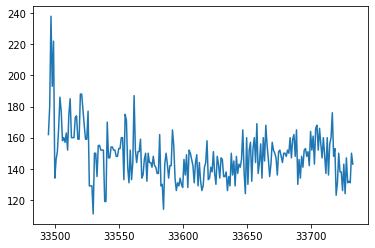

In [600]:
plt.plot(df_SBP)
plt.show()

In [601]:
# fix random seed for reproducibility
np.random.seed(7)

In [602]:
dataset = df_SBP.astype('float32')

In [603]:
dataset

,SBP
33495,162.0
33496,180.0
33497,238.0
33498,193.0
33499,222.0
...,...
33729,131.0
33730,132.0
33731,131.0
33732,150.0


In [604]:
# normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)


In [605]:
dataset

array([[0.4015748 ],
       [0.5433071 ],
       [0.99999994],
       [0.6456693 ],
       [0.87401575],
       [0.18110234],
       [0.2755906 ],
       [0.31496066],
       [0.43307084],
       [0.5905512 ],
       [0.5196851 ],
       [0.37007874],
       [0.38582677],
       [0.36220473],
       [0.4094488 ],
       [0.32283467],
       [0.50393695],
       [0.5826772 ],
       [0.38582677],
       [0.38582677],
       [0.38582677],
       [0.48818892],
       [0.49606293],
       [0.37795275],
       [0.37795275],
       [0.6062992 ],
       [0.6062992 ],
       [0.5275591 ],
       [0.44881886],
       [0.37795275],
       [0.37795275],
       [0.5196851 ],
       [0.14173228],
       [0.14173228],
       [0.14173228],
       [0.        ],
       [0.30708665],
       [0.30708665],
       [0.18897635],
       [0.3464567 ],
       [0.3464567 ],
       [0.32283467],
       [0.32283467],
       [0.32283467],
       [0.0629921 ],
       [0.0629921 ],
       [0.4645669 ],
       [0.283

In [606]:
# split into train and test sets
train_size = int(len(dataset) * 0.67)
test_size = len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]
print(len(train), len(test))

160 79


In [613]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-look_back-1):
		a = dataset[i:(i+look_back), 0]
		dataX.append(a)
		dataY.append(dataset[i + look_back, 0])
	return np.array(dataX), np.array(dataY)

In [614]:
# reshape into X=t and Y=t+1
look_back = 3 # 1
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

In [615]:
# reshape input to be [samples, time steps, features]
#trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1])) #no time steps
#testX = np.reshape(testX, (testX.shape[0], 1, testX.shape[1]))     #no time steps

trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1)) 
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

In [617]:
# create and fit the LSTM network
batch_size = 1
model = Sequential()
#model.add(LSTM(4, batch_input_shape=(batch_size, look_back, 1), stateful=True)) #time steps, memory between batches
model.add(LSTM(4, input_shape=(look_back, 1))) #time steps, no memory
# model.add(LSTM(4, input_shape=(1, look_back))) #no time steps, no memory
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])

#for i in range(3): # range(100)
#	model.fit(trainX, trainY, epochs=1, batch_size=batch_size, verbose=2, shuffle=False)
#	model.reset_states()

model.fit(trainX, trainY, epochs=30, batch_size=1, verbose=2) # epochs=10, epochs=100, epochs=30, epochs=3,

Epoch 1/30
 - 1s - loss: 0.1006 - mae: 0.2680
Epoch 2/30
 - 0s - loss: 0.0288 - mae: 0.1238
Epoch 3/30
 - 0s - loss: 0.0211 - mae: 0.1077
Epoch 4/30
 - 0s - loss: 0.0201 - mae: 0.1066
Epoch 5/30
 - 0s - loss: 0.0197 - mae: 0.1065
Epoch 6/30
 - 0s - loss: 0.0187 - mae: 0.1028
Epoch 7/30
 - 0s - loss: 0.0179 - mae: 0.1010
Epoch 8/30
 - 0s - loss: 0.0173 - mae: 0.0990
Epoch 9/30
 - 0s - loss: 0.0166 - mae: 0.0984
Epoch 10/30
 - 0s - loss: 0.0159 - mae: 0.0958
Epoch 11/30
 - 0s - loss: 0.0153 - mae: 0.0933
Epoch 12/30
 - 0s - loss: 0.0148 - mae: 0.0917
Epoch 13/30
 - 0s - loss: 0.0144 - mae: 0.0899
Epoch 14/30
 - 0s - loss: 0.0143 - mae: 0.0901
Epoch 15/30
 - 0s - loss: 0.0139 - mae: 0.0888
Epoch 16/30
 - 0s - loss: 0.0139 - mae: 0.0877
Epoch 17/30
 - 0s - loss: 0.0137 - mae: 0.0875
Epoch 18/30
 - 0s - loss: 0.0138 - mae: 0.0881
Epoch 19/30
 - 0s - loss: 0.0137 - mae: 0.0870
Epoch 20/30
 - 0s - loss: 0.0136 - mae: 0.0868
Epoch 21/30
 - 0s - loss: 0.0135 - mae: 0.0862
Epoch 22/30
 - 0s - lo

In [618]:
# make predictions
#trainPredict = model.predict(trainX, batch_size=batch_size) #memory between batches
trainPredict = model.predict(trainX) # no memory
#model.reset_states() #memory between batches
#testPredict = model.predict(testX, batch_size=batch_size) #memory between bathes
testPredict = model.predict(testX) # no memory

# invert predictions
trainPredict = scaler.inverse_transform(trainPredict)
trainY = scaler.inverse_transform([trainY])
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform([testY])

# calculate root mean squared error
trainScore = math.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = math.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))

Train Score: 14.55 RMSE
Test Score: 10.89 RMSE


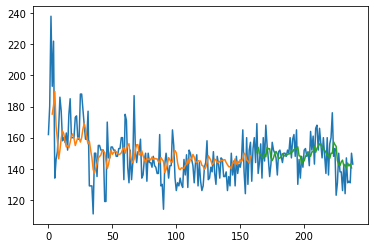

In [619]:
# shift train predictions for plotting
trainPredictPlot = np.empty_like(dataset)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[look_back:len(trainPredict)+look_back, :] = trainPredict

# shift test predictions for plotting
testPredictPlot = np.empty_like(dataset)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(trainPredict)+(look_back*2)+1:len(dataset)-1, :] = testPredict

# plot baseline and predictions
plt.plot(scaler.inverse_transform(dataset))

#plt.plot(dataset)
plt.plot(trainPredictPlot)
plt.plot(testPredictPlot)
plt.show()